In [1]:
import numpy as np
import matplotlib.pyplot as plt


def infer_box2_from_box1(box1_coords, pattern_height):
    (y_min, y_max), (x_min, x_max) = box1_coords
    box2_y_min = pattern_height - y_max
    box2_y_max = pattern_height - y_min
    return ((box2_y_min, box2_y_max), (x_min, x_max))


def calculate_box_asymmetry_score(diffraction_pattern, box1_coords, box2_coords):
    """
    Calculate asymmetry score using masked center of mass approach.
    Each box COM is computed separately; the midpoint y-displacement from
    the pattern centre is returned as a percentage of pattern height.
    """
    if hasattr(diffraction_pattern, "array"):
        pattern = np.array(diffraction_pattern.array)
    else:
        pattern = np.array(diffraction_pattern)
    pattern = np.asarray(pattern, dtype=np.float64)
    if pattern.ndim > 2:
        pattern = np.squeeze(pattern)

    ny, nx = pattern.shape

    def parse_coords(coords):
        (y_min, y_max), (x_min, x_max) = coords
        if 0 <= y_min <= 1 and 0 <= y_max <= 1:
            y_min, y_max = int(y_min * ny), int(y_max * ny)
        if 0 <= x_min <= 1 and 0 <= x_max <= 1:
            x_min, x_max = int(x_min * nx), int(x_max * nx)
        y_min = max(0, min(int(y_min), ny - 1))
        y_max = max(0, min(int(y_max), ny))
        x_min = max(0, min(int(x_min), nx - 1))
        x_max = max(0, min(int(x_max), nx))
        return y_min, y_max, x_min, x_max

    y1_min, y1_max, x1_min, x1_max = parse_coords(box1_coords)
    y2_min, y2_max, x2_min, x2_max = parse_coords(box2_coords)

    mask1 = np.zeros((ny, nx), dtype=bool)
    mask2 = np.zeros((ny, nx), dtype=bool)
    mask1[y1_min:y1_max, x1_min:x1_max] = True
    mask2[y2_min:y2_max, x2_min:x2_max] = True

    from scipy.ndimage import center_of_mass

    com1 = center_of_mass(pattern * mask1)
    com2 = center_of_mass(pattern * mask2)

    midpoint_y = (com1[0] + com2[0]) / 2
    midpoint_x = (com1[1] + com2[1]) / 2
    dy = midpoint_y - ny / 2
    dx = midpoint_x - nx / 2
    com_y_displacement = -(dy / ny) * 100

    box1_region = pattern[y1_min:y1_max, x1_min:x1_max]
    box2_region = pattern[y2_min:y2_max, x2_min:x2_max]
    box1_intensity = np.sum(box1_region)
    box2_intensity = np.sum(box2_region)

    return {
        "com_y_displacement": com_y_displacement,
        "intensity_asymmetry": box1_intensity - box2_intensity,
        "y_displacement": dy,
        "x_displacement": dx,
        "midpoint_y": midpoint_y,
        "midpoint_x": midpoint_x,
        "box1_com_y": com1[0],
        "box1_com_x": com1[1],
        "box2_com_y": com2[0],
        "box2_com_x": com2[1],
        "total_intensity": box1_intensity + box2_intensity,
        "box1_intensity": box1_intensity,
        "box2_intensity": box2_intensity,
        "box1_mean": np.mean(box1_region),
        "box2_mean": np.mean(box2_region),
        "box1_coords": (y1_min, y1_max, x1_min, x1_max),
        "box2_coords": (y2_min, y2_max, x2_min, x2_max),
    }


In [2]:
# ── Per-material configuration ────────────────────────────────────────────────
# path: compiled asymmetry_data_grid.npz from a tilt-grid run
# full_box: (y_min, y_max, x_min, x_max) in the 4× upscaled patterns
# top-third box is derived automatically as the first 1/3 of full_box height
# cell, nrep: in-plane cell (axis 0 polar, axis 1) and supercell repeats, for the
#   reciprocal calibration 1/(nrep*a) A^-1 per px. Same supercells as the
#   short-range runs; checked on the zero-tilt grid patterns (PTO Bragg spacing
#   30 px on axis 0, zone_axis_ratio 1.015 -> zone [100], polar on axis 0).

MATERIALS = {
    "PTO": {
        "formula": r"PbTiO$_3$", "abbr": "PTO",
        "path": "../data/grids/kikuchi/PTO_kikuchi_grid.npz",
        "full_box": (800, 1400, 1988, 2108),
        "pattern_height": 4096,
        "corrupted_indices": set(),
        "cell": (3.9423, 3.8862), "nrep": 30,
    },
    "BTO": {
        "formula": r"BaTiO$_3$", "abbr": "BTO",
        "path": "../data/grids/kikuchi/BTO_kikuchi_grid.npz",
        "full_box": (800, 1400, 1988, 2108),
        "pattern_height": 4096,
        "corrupted_indices": set(),
        "cell": (4.0230, 3.9905), "nrep": 30,
    },
    "Boracite": {
        "formula": r"Cu$_3$B$_7$ClO$_{13}$", "abbr": "boracite",
        "path": "../data/grids/kikuchi/Boracite_kikuchi_grid.npz",
        "full_box": (800, 1400, 1988, 2108),
        "pattern_height": 4096,
        "corrupted_indices": set(),
        "cell": (17.1032, 17.1032), "nrep": 7,
        "extent": (169.31, 169.31),   # abTEM box (-45 deg rotated 7x7 cell); = kikuchi_com.BORACITE_EXTENT
    },
}
for cfg in MATERIALS.values():
    a0, a1 = cfg["cell"]; n = cfg["nrep"]
    e0, e1 = cfg.get("extent", (n*a0, n*a1))   # simulation box (A)
    cfg["kpp"] = (1.0 / e0, 1.0 / e1)           # inverse angstrom per px


In [3]:
def process_material(name, cfg):
    data = np.load(cfg["path"])

    y_min, y_max, x_min, x_max = cfg["full_box"]
    third_h = (y_max - y_min) // 3
    box1 = ((y_min, y_min + third_h), (x_min, x_max))
    box2 = infer_box2_from_box1(box1, cfg["pattern_height"])
    full_box1 = ((y_min, y_max), (x_min, x_max))
    full_box2 = infer_box2_from_box1(full_box1, cfg["pattern_height"])
    print(f"{name}: top-third box1={box1}, box2={box2}")

    tilt_y = data["tilt_y_values"]  # (n_y,)
    tilt_x = data["tilt_x_values"]  # (n_x,)

    # Pre-computed full-box COM displacement grid (n_y, n_x)
    com_full_box = data["horizontal_boxes_com_y_displacement"]

    # Zero-tilt image and top-third COM — computed from raw images if available
    zero_tilt_image = None
    com_top_third = None

    if "diffraction_images" in data.files:
        images = data["diffraction_images"]  # (n_y, n_x, H, W)
        n_y, n_x = images.shape[0], images.shape[1]
        cy, cx = n_y // 2, n_x // 2
        zero_tilt_image = np.asarray(images[cy, cx], dtype=np.float64)

        print(f"  {name}: computing top-third COM across {n_y}×{n_x} grid…")
        com_rows = []
        corrupted = cfg.get("corrupted_indices", set())
        for iy in range(n_y):
            row_vals = []
            for ix in range(n_x):
                flat_idx = iy * n_x + ix
                if flat_idx in corrupted:
                    row_vals.append(np.nan)
                    continue
                diff = np.asarray(images[iy, ix], dtype=np.float64)
                result = calculate_box_asymmetry_score(diff, box1, box2)
                row_vals.append(result["com_y_displacement"])
            com_rows.append(row_vals)
        com_top_third = np.array(com_rows)  # (n_y, n_x)
    else:
        print(
            f"  {name}: diffraction_images not found in NPZ — skipping top-third heatmap."
        )

    return {
        "tilt_y": tilt_y,
        "tilt_x": tilt_x,
        "com_top_third": com_top_third,
        "com_full_box": com_full_box,
        "zero_tilt_image": zero_tilt_image,
        "box1": box1,
        "box2": box2,
        "full_box1": full_box1,
        "full_box2": full_box2,
    }


results = {}
for name, cfg in MATERIALS.items():
    results[name] = process_material(name, cfg)

PTO: top-third box1=((800, 1000), (1988, 2108)), box2=((3096, 3296), (1988, 2108))


  PTO: computing top-third COM across 9×9 grid…


BTO: top-third box1=((800, 1000), (1988, 2108)), box2=((3096, 3296), (1988, 2108))


  BTO: computing top-third COM across 9×9 grid…


Boracite: top-third box1=((800, 1000), (1988, 2108)), box2=((3096, 3296), (1988, 2108))


  Boracite: computing top-third COM across 9×9 grid…


In [4]:
# ── Corrected metric for the corrected_final figure (kikuchi_com) ──────────────
# The cells above keep the published metric (1-px biased mirror, midpoint of the two
# box centroids, % of pattern height, FULL_BOX for boracite). corrected_final uses the
# short-range notebook's metric instead: exact mirror box, masked union COM, A^-1,
# boracite on its 40-100 mrad angular box. Cached in cache_grid/ (raw masked_com, px).
import os, sys
sys.path.insert(0, "..")
from polarisation_direction import P_REVERSED
from kikuchi_com import FULL_BOX, angular_box, third_box, mirror_box, masked_com, stream_patterns

_h, _m, _e, _c = 6.62607015e-34, 9.1093837015e-31, 1.602176634e-19, 299792458.0
LAMBDA = _h / np.sqrt(2*_m*_e*300e3) / np.sqrt(1 + _e*300e3/(2*_m*_c**2)) * 1e10  # 0.019687 A
CACHE = "cache_grid"
os.makedirs(CACHE, exist_ok=True)
for name, cfg in MATERIALS.items():
    k0, k1 = cfg["kpp"]
    cfg["box"] = (angular_box(LAMBDA * k0 * 1e3, LAMBDA * k1 * 1e3, (40.0, 100.0))
                  if name == "Boracite" else FULL_BOX)


def corrected(name, cfg):
    box = tuple(int(v) for v in cfg["box"])
    path = os.path.join(CACHE, f"{name}.npz")
    if os.path.exists(path):
        d = np.load(path)
        if tuple(int(v) for v in d["box"]) == box:
            return {k: d[k] for k in d.files}
    shape = (len(results[name]["tilt_y"]), len(results[name]["tilt_x"]))
    full, third = [], []
    for p in stream_patterns(cfg["path"]):          # (n_y, n_x) order, C-contiguous
        full.append(masked_com(p, box))
        third.append(masked_com(p, third_box(box)))
    out = dict(box=np.array(box), full=np.reshape(full, shape), third=np.reshape(third, shape))
    np.savez(path, **out)
    return out


for name, cfg in MATERIALS.items():
    c, res = corrected(name, cfg), results[name]
    for key in ("full", "third"):
        v = -c[key] * cfg["kpp"][0]                  # + = top (low row index) brighter, A^-1
        # P towards the top box: PTO mirrored, y(ty, tx) -> -y(-ty, tx); BTO/boracite as built
        res[f"final_{key}"] = v if P_REVERSED[name] else -v[::-1, :]
    b = tuple(int(v) for v in c["box"])
    res["final_box1"], res["final_third1"] = b, third_box(b)
    i0 = len(res["tilt_y"]) // 2
    print(f"{name:9s} box {b}  zero-tilt full {res['final_full'][i0, i0]:+.4f} A^-1, "
          f"third {res['final_third'][i0, i0]:+.4f} A^-1")


PTO       box (800, 1400, 1988, 2108)  zero-tilt full +0.2084 A^-1, third +0.3277 A^-1
BTO       box (800, 1400, 1988, 2108)  zero-tilt full +0.0792 A^-1, third +0.1226 A^-1
Boracite  box (1188, 1705, 1962, 2134)  zero-tilt full +0.0662 A^-1, third +0.0768 A^-1


saved figures/kikuchi_grid.{pdf,png}


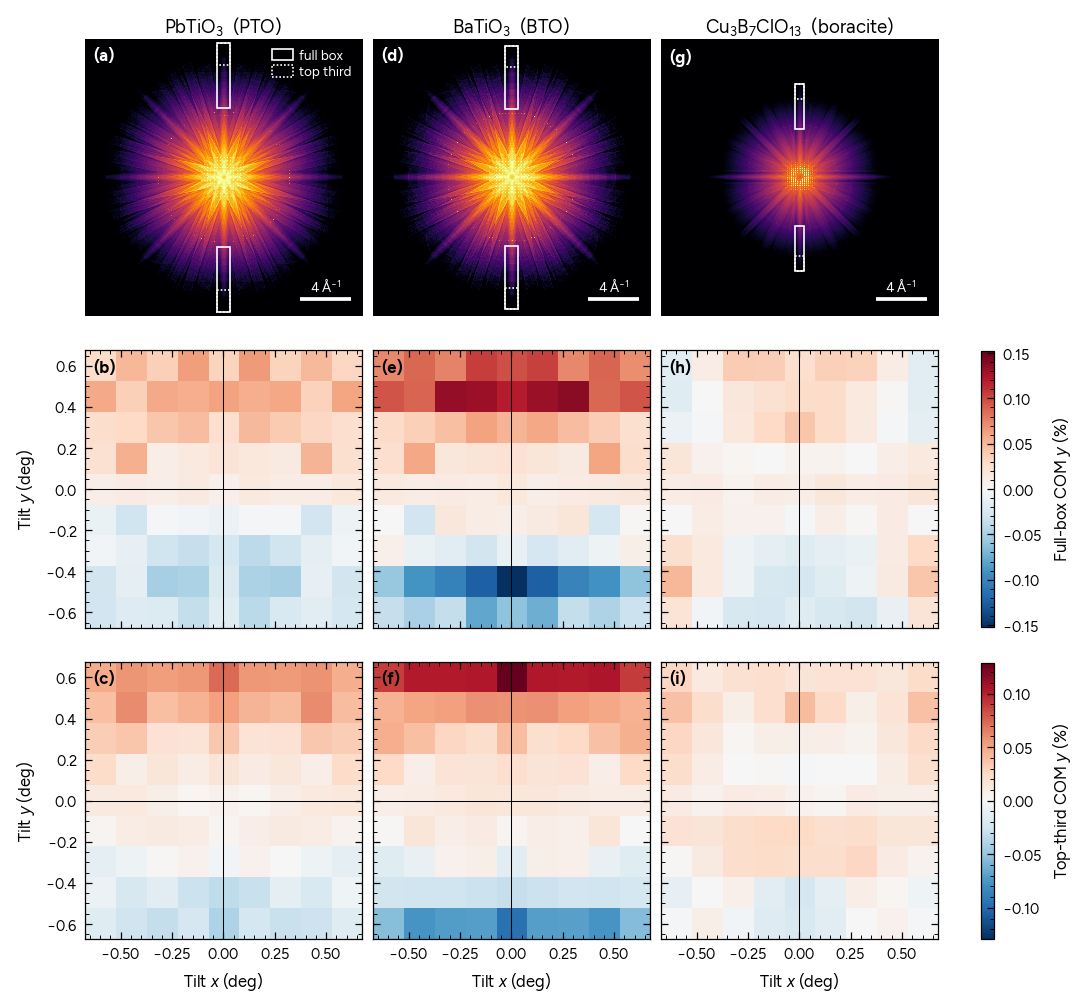

In [5]:
from matplotlib.patches import Rectangle
from matplotlib.colors import LogNorm

plt.style.use("paper")   # ~/.config/matplotlib/stylelib

# ── Figure: 180 mm double column, styled by the paper stylesheet ─────────────
MM = 1 / 25.4
N = 4096
FOV_INVA = 10.9      # half-width shown (A^-1); = 215 mrad, as in the short-range figure
SCALEBAR = 4.0       # inverse angstrom
FG, ZERO = "black", "black"
THIRD_LS = (0, (1, 1.2))

def panel_label(ax, txt, colour=FG):
    ax.text(0.03, 0.965, f"({txt})", transform=ax.transAxes, va="top", ha="left",
            fontsize=8, fontweight="bold", color=colour)


def box_patch(b, kpp0, kpp1, ls):
    """Rectangle for a (lo, hi, x0, x1) pixel box on the inverse-angstrom extent."""
    lo, hi, x0, x1 = b
    return Rectangle(((x0-N//2)*kpp1, (lo-N//2)*kpp0), (x1-x0)*kpp1, (hi-lo)*kpp0,
                     lw=0.8, edgecolor="white", facecolor="none", linestyle=ls)


def flat(box):
    (lo, hi), (x0, x1) = box
    return lo, hi, x0, x1


def heatmap(ax, grid, res, vmax, col, tilt_sign=1):
    if tilt_sign < 0:
        grid = grid[::-1, :]   # TILT_SIGN = -1 on tilt y, as in the 1D figures (ty symmetric)
    # tilt values are cell centres, so pad the extent by half a step
    hx = (res["tilt_x"][1] - res["tilt_x"][0]) / 2
    hy = (res["tilt_y"][1] - res["tilt_y"][0]) / 2
    im = ax.imshow(grid, origin="lower", aspect="equal", cmap="RdBu_r",
                   vmin=-vmax, vmax=vmax,
                   extent=[res["tilt_x"][0] - hx, res["tilt_x"][-1] + hx,
                           res["tilt_y"][0] - hy, res["tilt_y"][-1] + hy])
    ax.axhline(0, color=ZERO, lw=0.5)
    ax.axvline(0, color=ZERO, lw=0.5)
    if col == 0:
        ax.set_ylabel(r"Tilt $y$ (deg)")
    else:
        ax.set_yticklabels([])
    return im


def grid_figure(final=False, top_third=True):
    """final=False: published metric, as simulated.
    final=True: corrected metric (A^-1) in the common polarisation frame, P towards the TOP box
    (PTO mirrored, BTO/boracite as simulated); 'corrected_final/' prefix."""
    pre = "corrected_final/corrected_final_" if final else ""
    K_FULL, K_THIRD = ("final_full", "final_third") if final else ("com_full_box", "com_top_third")
    TS = -1 if final else 1   # final: tilt axis as the 1D figures; else as simulated
    UNIT = r"($\mathrm{\AA}^{-1}$)" if final else "(%)"
    has_top_third = top_third and any(res["com_top_third"] is not None for res in results.values())
    n_rows = 3 if has_top_third else 2
    mat_names = list(results.keys())

    vmax_full = max(np.nanmax(np.abs(res[K_FULL])) for res in results.values())
    if has_top_third:
        vmax_third = max(np.nanmax(np.abs(res[K_THIRD]))
                         for res in results.values() if res[K_THIRD] is not None)

    fig, axes = plt.subplots(n_rows, 3, figsize=(180*MM, 56*MM*n_rows), layout="constrained")
    fig.get_layout_engine().set(h_pad=0.01, w_pad=0.01, hspace=0.015, wspace=0.03)
    letters = iter("abcdefghi")


    for col, name in enumerate(mat_names):
        res, cfg = results[name], MATERIALS[name]
        kpp0, kpp1 = cfg["kpp"]

        # ══ Row 0: zero-tilt pattern on an inverse-angstrom extent ═══════════════
        ax = axes[0, col]
        h0, h1 = int(FOV_INVA / kpp0), int(FOV_INVA / kpp1)
        img = res["zero_tilt_image"][N//2-h0:N//2+h0, N//2-h1:N//2+h1]
        # colour limits from inside the antialias aperture (N/3 px radius) only
        yy, xx = np.ogrid[-h0:h0, -h1:h1]
        inside = np.hypot(yy*kpp0, xx*kpp1) < 0.97 * N * min(kpp0, kpp1) / 3
        vmin, vmax = np.percentile(img[inside & (img > 0)], [35, 99.8])
        kx, ky = h1*kpp1, h0*kpp0
        ax.imshow(np.clip(img, vmin, vmax), cmap="inferno", origin="upper",
                  extent=[-kx, kx, ky, -ky], aspect="equal",
                  norm=LogNorm(vmin=vmin, vmax=vmax), rasterized=True)

        # boxes exactly as used for the heatmaps below (same mirror convention)
        if final:
            full_boxes = (res["final_box1"], mirror_box(res["final_box1"]))
            third_boxes = (res["final_third1"], mirror_box(res["final_third1"]))
        else:
            full_boxes = (flat(res["full_box1"]), flat(res["full_box2"]))
            third_boxes = (flat(res["box1"]), flat(res["box2"]))
        for b in full_boxes:
            ax.add_patch(box_patch(b, kpp0, kpp1, "-"))
        if has_top_third:
            for b in third_boxes:
                ax.add_patch(box_patch(b, kpp0, kpp1, THIRD_LS))

        x_hi, y_lo = kx*0.92, ky*0.88
        ax.plot([x_hi - SCALEBAR, x_hi], [y_lo, y_lo], color="white", lw=1.8,
                solid_capstyle="butt", zorder=5)
        ax.text(x_hi - SCALEBAR/2, y_lo - ky*0.035, rf"{SCALEBAR:.0f} $\mathrm{{\AA}}^{{-1}}$",
                color="white", ha="center", va="bottom", fontsize=6.5, zorder=5)
        ax.set_xticks([]); ax.set_yticks([])
        for s in ax.spines.values():
            s.set_visible(False)
        panel_label(ax, next(letters), colour="white")
        if final:                                   # P points to the top (solid) box
            ax.annotate("", xy=(-kx*0.80, -ky*0.72), xytext=(-kx*0.80, -ky*0.44),
                        arrowprops=dict(arrowstyle="-|>", color="white", lw=1.0))
            ax.text(-kx*0.74, -ky*0.58, "P", color="white", va="center", fontsize=7, fontweight="bold")
        ax.set_title(rf"{cfg['formula']}  ({cfg['abbr']})", pad=3, fontsize=9)

        # ══ Row 1: full-box COM over the tilt grid ═══════════════════════════════
        ax = axes[1, col]
        im_full = heatmap(ax, res[K_FULL], res, vmax_full, col, TS)
        if not has_top_third:
            ax.set_xlabel(r"Tilt $x$ (deg)")
        else:
            ax.set_xticklabels([])
        panel_label(ax, next(letters))

        # ══ Row 2: top-third COM over the tilt grid ══════════════════════════════
        if has_top_third:
            ax = axes[2, col]
            if res[K_THIRD] is not None:
                im_third = heatmap(ax, res[K_THIRD], res, vmax_third, col, TS)
                ax.set_xlabel(r"Tilt $x$ (deg)")
                panel_label(ax, next(letters))
            else:
                ax.text(0.5, 0.5, "No image data", ha="center", va="center",
                        transform=ax.transAxes, color="gray")
                ax.axis("off")

    fig.colorbar(im_full, ax=axes[1, :], label=("Full-box COM $y$ " if has_top_third else "Kikuchi COM $y$ ") + UNIT, shrink=0.9)
    if has_top_third:
        fig.colorbar(im_third, ax=axes[2, :], label="Top-third COM $y$ " + UNIT, shrink=0.9)

    if has_top_third:
        leg = axes[0, 0].legend(
            [Rectangle((0, 0), 1, 1, ec="white", fc="none", lw=0.8),
             Rectangle((0, 0), 1, 1, ec="white", fc="none", lw=0.8, ls=THIRD_LS)],
            ["full box", "top third"],
            loc="upper right", handleheight=0.9,
        )
        for txt in leg.get_texts():
            txt.set_color("white")

    fig.savefig(f"figures/{pre}kikuchi_grid.pdf")
    fig.savefig(f"figures/{pre}kikuchi_grid.png")
    print(f"saved figures/{pre}kikuchi_grid.{{pdf,png}}")
    plt.show()


grid_figure()


saved figures/corrected_final/corrected_final_kikuchi_grid.{pdf,png}


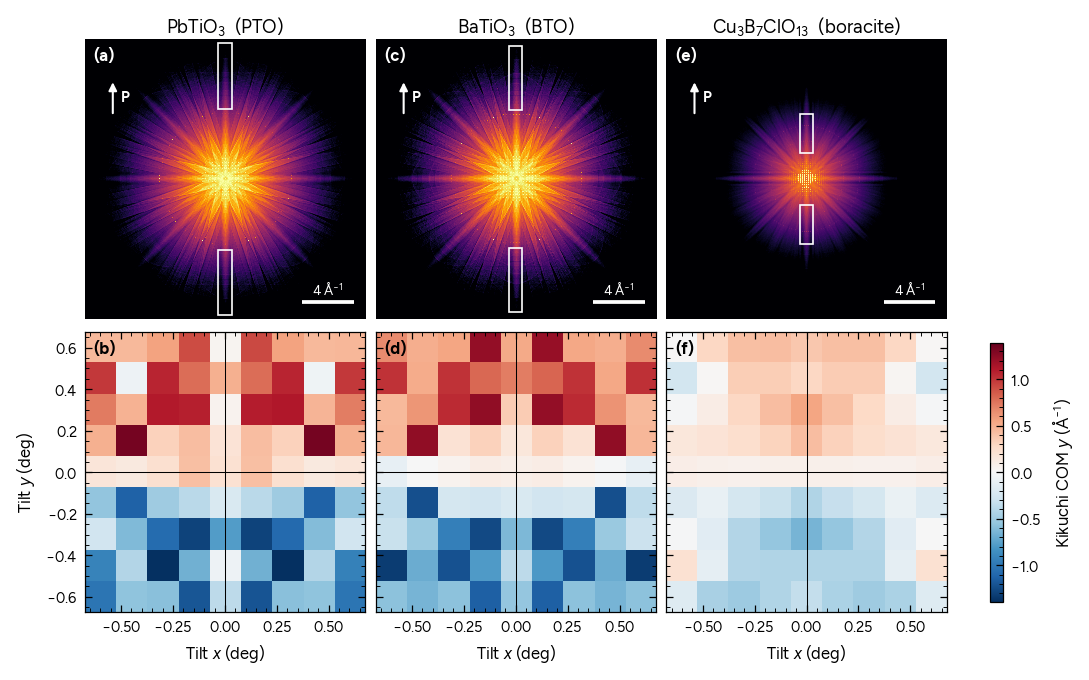

In [6]:
grid_figure(final=True, top_third=False)  # paper figure: full box only
